## Missing cross channel reference 

Missing Cross-Channel Reference. A valid textual reference to an earlier message on another channel is modified so that it refers to a different legitimate communication channel for which no matching earlier message from the same sender exists. Exactly one reference is corrupted per affected campaign. Message count, order, timestamps, channels, senders, recipients, entity identifiers and reference metadata remain unchanged. Severity is defined only by the proportion of affected campaigns: 10%, 30%, and 60%.

In [1]:
import importlib
import src.defects as defects
import pandas as pd
import numpy as np

importlib.reload(defects)

from src.defects import (
    find_missing_cross_channel_candidates
)

In [2]:
clean_campaigns = pd.read_csv(
    "../data/processed/clean_structured_campaigns.csv",
    parse_dates=["timestamp"]
)

In [3]:
entity_catalog = pd.read_csv(
    "../data/processed/entity_catalog.csv"
)


In [4]:
split_df = pd.read_csv(
    "../data/processed/structural_campaign_split.csv"
)

In [5]:
train_ids = set(
    split_df.loc[
        split_df["split"] == "train",
        "campaign_id"
    ]
)

eval_ids = set(
    split_df.loc[
        split_df["split"] == "evaluation",
        "campaign_id"
    ]
)


In [6]:
clean_campaigns_eval = (
    clean_campaigns[
        clean_campaigns["campaign_id"]
        .isin(eval_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

In [7]:
cross_channel_candidates = (
    find_missing_cross_channel_candidates(
        clean_campaigns_eval
    )
)

print(
    "Candidate injections:",
    len(
        cross_channel_candidates
    )
)

print(
    "Eligible campaigns:",
    cross_channel_candidates[
        "campaign_id"
    ].nunique()
)

print(
    "Required for 60% severity:",
    180
)

display(
    cross_channel_candidates.head(10)
)

Candidate injections: 300
Eligible campaigns: 300
Required for 60% severity: 180


,campaign_id,target_message_id,target_message_order,reference_id,reference_message_order,target_channel,original_reference_channel,replacement_channel,sender,original_text
0,C0003,C0003_M03,3,C0003_M01,1,email,sms,whatsapp,advisor_07,Following up here on the sms message I sent ea...
1,C0004,C0004_M03,3,C0004_M01,1,sms,email,whatsapp,advisor_17,Following up here on the email message I sent ...
2,C0006,C0006_M03,3,C0006_M01,1,whatsapp,sms,email,advisor_06,Following up here on the sms message I sent ea...
3,C0008,C0008_M03,3,C0008_M01,1,sms,email,whatsapp,advisor_15,Following up here on the email message I sent ...
4,C0010,C0010_M03,3,C0010_M01,1,sms,email,whatsapp,advisor_17,Following up here on the email message I sent ...
5,C0011,C0011_M03,3,C0011_M01,1,sms,whatsapp,email,advisor_14,Following up here on the whatsapp message I se...
6,C0024,C0024_M03,3,C0024_M01,1,sms,whatsapp,email,advisor_20,Following up here on the whatsapp message I se...
7,C0026,C0026_M03,3,C0026_M01,1,sms,whatsapp,email,advisor_09,Following up here on the whatsapp message I se...
8,C0030,C0030_M03,3,C0030_M01,1,email,whatsapp,sms,advisor_05,Following up here on the whatsapp message I se...
9,C0031,C0031_M03,3,C0031_M01,1,sms,whatsapp,email,advisor_07,Following up here on the whatsapp message I se...


In [8]:
importlib.reload(defects)

from src.defects import (
    make_missing_cross_channel_plan,
    inject_missing_cross_channel_reference
)

In [9]:
missing_cross_channel_plan = (
    make_missing_cross_channel_plan(
        clean_campaigns_eval,
        seed=42
    )
)

print(
    "Campaigns in plan:",
    len(missing_cross_channel_plan)
)

print(
    "Unique campaigns:",
    missing_cross_channel_plan[
        "campaign_id"
    ].nunique()
)

display(
    missing_cross_channel_plan.head(10)
)

Campaigns in plan: 300
Unique campaigns: 300


,campaign_id,target_message_id,target_message_order,reference_id,reference_message_order,target_channel,original_reference_channel,replacement_channel,sender,original_text,severity_rank
0,C0003,C0003_M03,3,C0003_M01,1,email,sms,whatsapp,advisor_07,Following up here on the sms message I sent ea...,27
1,C0004,C0004_M03,3,C0004_M01,1,sms,email,whatsapp,advisor_17,Following up here on the email message I sent ...,256
2,C0006,C0006_M03,3,C0006_M01,1,whatsapp,sms,email,advisor_06,Following up here on the sms message I sent ea...,46
3,C0008,C0008_M03,3,C0008_M01,1,sms,email,whatsapp,advisor_15,Following up here on the email message I sent ...,41
4,C0010,C0010_M03,3,C0010_M01,1,sms,email,whatsapp,advisor_17,Following up here on the email message I sent ...,141
5,C0011,C0011_M03,3,C0011_M01,1,sms,whatsapp,email,advisor_14,Following up here on the whatsapp message I se...,192
6,C0024,C0024_M03,3,C0024_M01,1,sms,whatsapp,email,advisor_20,Following up here on the whatsapp message I se...,284
7,C0026,C0026_M03,3,C0026_M01,1,sms,whatsapp,email,advisor_09,Following up here on the whatsapp message I se...,96
8,C0030,C0030_M03,3,C0030_M01,1,email,whatsapp,sms,advisor_05,Following up here on the whatsapp message I se...,122
9,C0031,C0031_M03,3,C0031_M01,1,sms,whatsapp,email,advisor_07,Following up here on the whatsapp message I se...,135


In [10]:
MISSING_REFERENCE_SEVERITIES = [
    0.10,
    0.30,
    0.60
]

missing_reference_results = {}

for severity in (
    MISSING_REFERENCE_SEVERITIES
):

    defective, audit = (
        inject_missing_cross_channel_reference(
            clean_campaigns_eval,
            missing_cross_channel_plan,
            severity=severity
        )
    )

    missing_reference_results[
        severity
    ] = {
        "defective": defective,
        "audit": audit
    }

    print(
        f"Severity {severity:.0%} | "
        f"Affected campaigns: "
        f"{len(audit)}"
    )

Severity 10% | Affected campaigns: 30
Severity 30% | Affected campaigns: 90
Severity 60% | Affected campaigns: 180


In [11]:
ids_10 = set(
    missing_reference_results[
        0.10
    ]["audit"]["campaign_id"]
)

ids_30 = set(
    missing_reference_results[
        0.30
    ]["audit"]["campaign_id"]
)

ids_60 = set(
    missing_reference_results[
        0.60
    ]["audit"]["campaign_id"]
)

assert ids_10.issubset(
    ids_30
)

assert ids_30.issubset(
    ids_60
)

print(
    "Nested severity validation passed."
)

print(
    len(ids_10),
    len(ids_30),
    len(ids_60)
)

Nested severity validation passed.
30 90 180


In [12]:
NON_TEXT_COLUMNS = [
    "campaign_id",
    "message_id",
    "message_order",
    "timestamp",
    "channel",
    "sender",
    "recipient",
    "entity_id",
    "reference_id",
    "parent_message_id"
]

for severity in (
    MISSING_REFERENCE_SEVERITIES
):

    defective = (
        missing_reference_results[
            severity
        ]["defective"]
    )

    assert (
        clean_campaigns_eval[
            NON_TEXT_COLUMNS
        ]
        .reset_index(drop=True)
        .equals(
            defective[
                NON_TEXT_COLUMNS
            ]
            .reset_index(drop=True)
        )
    )

print(
    "All non-text fields were preserved."
)

All non-text fields were preserved.


In [13]:
for severity in (
    MISSING_REFERENCE_SEVERITIES
):

    clean = (
        clean_campaigns_eval
        .set_index("message_id")
    )

    defective = (
        missing_reference_results[
            severity
        ]["defective"]
        .set_index("message_id")
    )

    changed = (
        clean["text"]
        != defective["text"]
    )

    changed_messages = (
        changed[changed]
        .index
    )

    changed_campaigns = (
        clean.loc[
            changed_messages,
            "campaign_id"
        ]
        .value_counts()
    )

    assert (
        changed_campaigns == 1
    ).all()

    expected = int(
        round(
            severity * 300
        )
    )

    assert (
        len(changed_messages)
        == expected
    )

    print(
        f"{severity:.0%}: "
        f"{len(changed_messages)} "
        "messages changed, "
        "exactly one per affected campaign"
    )

10%: 30 messages changed, exactly one per affected campaign
30%: 90 messages changed, exactly one per affected campaign
60%: 180 messages changed, exactly one per affected campaign


In [14]:
display(
    missing_reference_results[
        0.10
    ]["audit"][
        [
            "campaign_id",
            "target_message_order",
            "reference_id",
            "original_reference_channel",
            "replacement_channel",
            "original_text",
            "defective_text"
        ]
    ].head(10)
)

,campaign_id,target_message_order,reference_id,original_reference_channel,replacement_channel,original_text,defective_text
0,C0003,3,C0003_M01,sms,whatsapp,Following up here on the sms message I sent ea...,Following up here on the whatsapp message I se...
1,C0064,3,C0064_M01,sms,whatsapp,Following up here on the sms message I sent ea...,Following up here on the whatsapp message I se...
2,C0078,3,C0078_M01,email,whatsapp,Following up here on the email message I sent ...,Following up here on the whatsapp message I se...
3,C0159,3,C0159_M01,sms,email,Following up here on the sms message I sent ea...,Following up here on the email message I sent ...
4,C0193,3,C0193_M01,whatsapp,email,Following up here on the whatsapp message I se...,Following up here on the email message I sent ...
5,C0216,3,C0216_M01,whatsapp,sms,Following up here on the whatsapp message I se...,Following up here on the sms message I sent ea...
6,C0228,3,C0228_M01,email,whatsapp,Following up here on the email message I sent ...,Following up here on the whatsapp message I se...
7,C0262,3,C0262_M01,sms,email,Following up here on the sms message I sent ea...,Following up here on the email message I sent ...
8,C0306,3,C0306_M01,email,whatsapp,Following up here on the email message I sent ...,Following up here on the whatsapp message I se...
9,C0315,3,C0315_M01,sms,email,Following up here on the sms message I sent ea...,Following up here on the email message I sent ...


### Missing Cross-Channel Reference Injection

All 300 evaluation campaigns contained a valid candidate for the
Missing Cross-Channel Reference defect, exceeding the 180 campaigns
required for the maximum 60% prevalence condition. Therefore, severity
could be defined directly over the complete evaluation set without
eligibility-based filtering.

For each affected campaign, exactly one valid textual reference to an
earlier message on another channel was corrupted by replacing the
referenced channel with a different communication channel for which no
matching earlier message from the same sender existed. The target
message itself remained on its original channel.

Severity was defined only through defect prevalence: 30, 90, and 180
of the 300 evaluation campaigns were modified at the 10%, 30%, and
60% levels. A fixed injection plan and nested campaign subsets were
used across severity levels.

Only the target message text was modified. Message count, message
order, timestamps, actual communication channels, senders, recipients,
entity identifiers, reference identifiers, and parent-message
relationships were preserved. Reference metadata was retained solely
as experimental ground truth and was not provided to the semantic
representation or statistical tests.

In [15]:
import src.representations as representations

importlib.reload(representations)

from src.representations import (
    serialize_campaign_dataset,
    split_campaign_into_chunks,
    encode_serialized_campaigns
)

In [16]:
# import the same semantic configuration from EI
import json

with open(
    "../results/"
    "semantic_embedding_configuration.json",
    "r"
) as f:

    semantic_config = json.load(f)


MODEL_NAME = (
    semantic_config["model"]
)

MODEL_REVISION = (
    semantic_config["revision"]
)

SEMANTIC_MMD_SIGMA = (
    semantic_config["mmd_sigma"]
)

EMBEDDING_BATCH_SIZE = 64


print(
    "Model:",
    MODEL_NAME
)

print(
    "Frozen revision:",
    MODEL_REVISION
)

print(
    "Frozen MMD sigma:",
    SEMANTIC_MMD_SIGMA
)

Model: sentence-transformers/all-MiniLM-L6-v2
Frozen revision: 1110a243fdf4706b3f48f1d95db1a4f5529b4d41
Frozen MMD sigma: 0.4312044032354748


In [17]:
from sentence_transformers import (
    SentenceTransformer
)

embedding_model = SentenceTransformer(
    MODEL_NAME,
    revision=MODEL_REVISION
)

print(
    "Embedding dimension:",
    embedding_model
    .get_sentence_embedding_dimension()
)

print(
    "Maximum sequence length:",
    embedding_model.max_seq_length
)

Embedding dimension: 384
Maximum sequence length: 256


In [18]:
missing_reference_serialized = {}

missing_reference_serialized[
    "clean"
] = serialize_campaign_dataset(
    clean_campaigns_eval
)

print(
    "Clean serialized:",
    missing_reference_serialized[
        "clean"
    ].shape
)

Clean serialized: (300, 2)


In [19]:
for severity in [
    0.10,
    0.30,
    0.60
]:

    defective_campaigns = (
        missing_reference_results[
            severity
        ]["defective"]
    )

    missing_reference_serialized[
        severity
    ] = (
        serialize_campaign_dataset(
            defective_campaigns
        )
    )

    print(
        f"{severity:.0%}: "
        f"{missing_reference_serialized[severity].shape}"
    )

10%: (300, 2)
30%: (300, 2)
60%: (300, 2)


In [20]:
expected_changes = {
    0.10: 30,
    0.30: 90,
    0.60: 180
}


clean_serialized = (
    missing_reference_serialized[
        "clean"
    ]
    .set_index(
        "campaign_id"
    )
    .sort_index()
)


for severity in [
    0.10,
    0.30,
    0.60
]:

    defective_serialized = (
        missing_reference_serialized[
            severity
        ]
        .set_index(
            "campaign_id"
        )
        .sort_index()
    )

    assert (
        clean_serialized.index.tolist()
        ==
        defective_serialized.index.tolist()
    )

    changed = (
        clean_serialized[
            "serialized_text"
        ]
        !=
        defective_serialized[
            "serialized_text"
        ]
    )

    n_changed = int(
        changed.sum()
    )

    print(
        f"{severity:.0%}: "
        f"{n_changed} serialized campaigns changed"
    )

    assert (
        n_changed
        ==
        expected_changes[
            severity
        ]
    )


print(
    "Serialization alignment checks passed."
)

10%: 30 serialized campaigns changed
30%: 90 serialized campaigns changed
60%: 180 serialized campaigns changed
Serialization alignment checks passed.


In [21]:
length_summary = []

for condition in [
    "clean",
    0.10,
    0.30,
    0.60
]:

    lengths = []

    for text in (
        missing_reference_serialized[
            condition
        ]["serialized_text"]
    ):

        encoded = (
            embedding_model.tokenizer(
                text,
                add_special_tokens=True,
                truncation=False
            )
        )

        lengths.append(
            len(
                encoded[
                    "input_ids"
                ]
            )
        )

    length_summary.append({
        "condition":
            condition,

        "n_campaigns":
            len(lengths),

        "mean_tokens":
            np.mean(
                lengths
            ),

        "max_tokens":
            max(lengths),

        "over_limit":
            sum(
                length
                >
                embedding_model.max_seq_length
                for length in lengths
            )
    })


missing_reference_length_summary = (
    pd.DataFrame(
        length_summary
    )
)

display(
    missing_reference_length_summary
)

Token indices sequence length is longer than the specified maximum sequence length for this model (259 > 256). Running this sequence through the model will result in indexing errors


,condition,n_campaigns,mean_tokens,max_tokens,over_limit
0,clean,300,200.063333,261,8
1,0.1,300,200.096667,261,8
2,0.3,300,200.090000,261,8
3,0.6,300,200.136667,261,9


In [22]:
chunk_validation_records = []

for condition in [
    "clean",
    0.10,
    0.30,
    0.60
]:

    serialized_df = (
        missing_reference_serialized[
            condition
        ]
    )

    for _, row in (
        serialized_df.iterrows()
    ):

        chunks = (
            split_campaign_into_chunks(
                row[
                    "serialized_text"
                ],
                embedding_model
            )
        )

        chunk_lengths = []

        for chunk in chunks:

            length = len(
                embedding_model.tokenizer(
                    chunk,
                    add_special_tokens=True,
                    truncation=False
                )[
                    "input_ids"
                ]
            )

            chunk_lengths.append(
                length
            )

            assert (
                length
                <=
                embedding_model.max_seq_length
            )

        chunk_validation_records.append({
            "condition":
                condition,

            "campaign_id":
                row[
                    "campaign_id"
                ],

            "n_chunks":
                len(chunks),

            "max_chunk_tokens":
                max(
                    chunk_lengths
                )
        })


missing_reference_chunk_validation = (
    pd.DataFrame(
        chunk_validation_records
    )
)


print(
    "Maximum chunk length:",
    missing_reference_chunk_validation[
        "max_chunk_tokens"
    ].max()
)

print(
    "Model limit:",
    embedding_model.max_seq_length
)

print(
    "Campaign-condition instances "
    "requiring more than one chunk:",
    (
        missing_reference_chunk_validation[
            "n_chunks"
        ] > 1
    ).sum()
)

print(
    "Maximum chunks for one campaign:",
    missing_reference_chunk_validation[
        "n_chunks"
    ].max()
)

print(
    "All chunks fit within the model limit."
)

Maximum chunk length: 256
Model limit: 256
Campaign-condition instances requiring more than one chunk: 33
Maximum chunks for one campaign: 2
All chunks fit within the model limit.


In [23]:
missing_reference_embedding_arrays = {}
missing_reference_embedding_runtimes = {}

conditions = [
    "clean",
    0.10,
    0.30,
    0.60
]


for condition in conditions:

    embeddings, runtime = (
        encode_serialized_campaigns(
            missing_reference_serialized[
                condition
            ],
            embedding_model,
            batch_size=(
                EMBEDDING_BATCH_SIZE
            )
        )
    )

    missing_reference_embedding_arrays[
        condition
    ] = embeddings

    missing_reference_embedding_runtimes[
        condition
    ] = runtime

    print(
        f"{str(condition):>5} | "
        f"shape={embeddings.shape} | "
        f"runtime={runtime:.2f} s"
    )

Campaigns: 300
Chunks to encode: 308


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

clean | shape=(300, 384) | runtime=44.82 s
Campaigns: 300
Chunks to encode: 308


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

  0.1 | shape=(300, 384) | runtime=40.02 s
Campaigns: 300
Chunks to encode: 308


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

  0.3 | shape=(300, 384) | runtime=39.62 s
Campaigns: 300
Chunks to encode: 309


Batches:   0%|          | 0/5 [00:00<?, ?it/s]

  0.6 | shape=(300, 384) | runtime=39.49 s


In [24]:
for condition in conditions:

    X = (
        missing_reference_embedding_arrays[
            condition
        ]
    )

    assert (
        X.shape
        ==
        (300, 384)
    )

    assert np.isfinite(
        X
    ).all()

    norms = np.linalg.norm(
        X,
        axis=1
    )

    assert np.allclose(
        norms,
        1.0,
        atol=1e-5
    )


print(
    "All embedding matrices passed validation."
)

All embedding matrices passed validation.


In [25]:
EMBEDDING_FEATURES = [
    f"emb_{i:03d}"
    for i in range(
        384
    )
]

missing_reference_embeddings = {}


for condition in conditions:

    embedding_df = pd.DataFrame(
        missing_reference_embedding_arrays[
            condition
        ],
        columns=EMBEDDING_FEATURES
    )

    embedding_df.insert(
        0,
        "campaign_id",
        missing_reference_serialized[
            condition
        ][
            "campaign_id"
        ].to_numpy()
    )

    missing_reference_embeddings[
        condition
    ] = embedding_df


print(
    "Embedding features:",
    len(
        EMBEDDING_FEATURES
    )
)

print(
    "Clean embedding DataFrame:",
    missing_reference_embeddings[
        "clean"
    ].shape
)

Embedding features: 384
Clean embedding DataFrame: (300, 385)


In [26]:
clean_embeddings_indexed = (
    missing_reference_embeddings[
        "clean"
    ]
    .set_index(
        "campaign_id"
    )
    .sort_index()
)

print(
    "Clean indexed shape:",
    clean_embeddings_indexed.shape
)

Clean indexed shape: (300, 384)


In [27]:
clean_embeddings_indexed = (
    missing_reference_embeddings[
        "clean"
    ]
    .set_index(
        "campaign_id"
    )
    .sort_index()
)

print(
    "Clean indexed shape:",
    clean_embeddings_indexed.shape
)

Clean indexed shape: (300, 384)


In [28]:
embedding_change_records = []


for severity in [
    0.10,
    0.30,
    0.60
]:

    defective = (
        missing_reference_embeddings[
            severity
        ]
        .set_index(
            "campaign_id"
        )
        .sort_index()
    )

    differences = (
        defective[
            EMBEDDING_FEATURES
        ].to_numpy()
        -
        clean_embeddings_indexed[
            EMBEDDING_FEATURES
        ].to_numpy()
    )

    distances = np.linalg.norm(
        differences,
        axis=1
    )

    affected_ids = set(
        missing_reference_results[
            severity
        ]["audit"][
            "campaign_id"
        ]
    )

    ordered_ids = (
        clean_embeddings_indexed
        .index
        .to_numpy()
    )

    affected_mask = np.array([
        campaign_id
        in affected_ids

        for campaign_id
        in ordered_ids
    ])

    embedding_change_records.append({
        "severity":
            severity,

        "affected_campaigns":
            int(
                affected_mask.sum()
            ),

        "mean_change_all":
            distances.mean(),

        "mean_change_affected":
            distances[
                affected_mask
            ].mean(),

        "median_change_affected":
            np.median(
                distances[
                    affected_mask
                ]
            ),

        "max_change":
            distances.max()
    })


missing_reference_embedding_change_summary = (
    pd.DataFrame(
        embedding_change_records
    )
)

display(
    missing_reference_embedding_change_summary
)

,severity,affected_campaigns,mean_change_all,mean_change_affected,median_change_affected,max_change
0,0.1,30,0.015933,0.159332,0.128931,0.521489
1,0.3,90,0.041098,0.136995,0.115084,0.521489
2,0.6,180,0.084091,0.140151,0.118751,0.521489


In [29]:
from pathlib import Path

Path(
    "../data/processed"
).mkdir(
    exist_ok=True
)

Path(
    "../results"
).mkdir(
    exist_ok=True
)


for condition in conditions:

    condition_name = (
        "clean"
        if condition == "clean"
        else
        f"{int(condition * 100)}pct"
    )

    np.save(
        "../data/processed/"
        f"missing_reference_embeddings_"
        f"{condition_name}.npy",

        missing_reference_embedding_arrays[
            condition
        ]
    )


missing_reference_embedding_change_summary.to_csv(
    "../results/"
    "missing_reference_"
    "embedding_change_summary.csv",
    index=False
)

print(
    "Missing Cross-Channel Reference "
    "embeddings saved."
)

Missing Cross-Channel Reference embeddings saved.


### Semantic Representation Response

The frozen semantic representation successfully encoded all Missing
Cross-Channel Reference conditions using the same serialization,
message-preserving chunking procedure, pretrained encoder, and embedding
configuration previously used for Entity Inconsistency.

All resulting chunks remained within the 256-token model limit, and no
campaign required more than two chunks. Across the four conditions,
33 campaign-condition instances required more than one chunk.

The semantic embedding responded consistently to the injected defect.
Among affected campaigns, the mean Euclidean displacement from the clean
embedding was 0.1593, 0.1370, and 0.1402 at 10%, 30%, and 60% prevalence,
respectively. Thus, the magnitude of the representation-level change per
affected campaign remained approximately stable across severity levels.

In contrast, the mean change across all campaigns increased from 0.0159
at 10% prevalence to 0.0411 at 30% and 0.0841 at 60%. This is consistent
with the experimental design, in which severity is controlled through
the fraction of affected campaigns rather than through the magnitude of
the individual corruption.

Compared with Entity Inconsistency, the Missing Cross-Channel Reference
intervention produces a larger average displacement in the general
semantic embedding. This observation concerns representation response
only and should not be interpreted as metric detection power. Detection
will be evaluated separately using the frozen paired C2ST, MMD, and
Energy Distance procedures.

100 paired campaigns / repetition
200 repetitions
100 permutations
alpha = 0.05
same semantic embeddings
same frozen MMD sigma
same 200 sampling subsets used for Entity Inconsistency

In [30]:
from src.metrics import (
    get_paired_samples,
    c2st_paired,
    mmd_paired_permutation_test,
    energy_paired_permutation_test,
    extract_metric_result
)

In [31]:
N_PAIRS = 100
N_REPS = 200
N_PERMUTATIONS = 100

ALPHA = 0.05
BASE_SEED = 42

SEVERITIES = [
    0.10,
    0.30,
    0.60
]

print(
    "Pairs per repetition:",
    N_PAIRS
)

print(
    "Repetitions:",
    N_REPS
)

print(
    "Permutations:",
    N_PERMUTATIONS
)

print(
    "Alpha:",
    ALPHA
)

print(
    "Frozen semantic MMD sigma:",
    SEMANTIC_MMD_SIGMA
)

Pairs per repetition: 100
Repetitions: 200
Permutations: 100
Alpha: 0.05
Frozen semantic MMD sigma: 0.4312044032354748


In [32]:
sampling_plan_df = pd.read_csv(
    "../results/"
    "entity_inconsistency_sampling_plan.csv"
)

print(
    "Sampling plan rows:",
    len(sampling_plan_df)
)

print(
    "Repetitions:",
    sampling_plan_df[
        "repetition"
    ].nunique()
)

Sampling plan rows: 20000
Repetitions: 200


In [33]:
sampling_plan = {
    int(rep): group[
        "campaign_id"
    ].to_numpy()

    for rep, group
    in sampling_plan_df.groupby(
        "repetition"
    )
}

In [34]:
assert len(
    sampling_plan
) == N_REPS

assert all(
    len(ids) == N_PAIRS
    for ids in sampling_plan.values()
)

print(
    "Same sampling plan successfully restored."
)

Same sampling plan successfully restored.


In [35]:
test_ids = (
    sampling_plan[0]
)

P_test, Q_test = (
    get_paired_samples(
        missing_reference_embeddings[
            "clean"
        ],
        missing_reference_embeddings[
            0.30
        ],
        test_ids,
        EMBEDDING_FEATURES
    )
)

print(
    "P shape:",
    P_test.shape
)

print(
    "Q shape:",
    Q_test.shape
)

print(
    "Identical matrices:",
    np.allclose(
        P_test,
        Q_test
    )
)

P shape: (100, 384)
Q shape: (100, 384)
Identical matrices: False


In [36]:
c2st_test = c2st_paired(
    P_test,
    Q_test,
    test_size=0.5,
    n_permutations=N_PERMUTATIONS,
    seed=BASE_SEED,
    alpha=ALPHA
)

mmd_test = (
    mmd_paired_permutation_test(
        P_test,
        Q_test,
        sigma=SEMANTIC_MMD_SIGMA,
        n_permutations=N_PERMUTATIONS,
        seed=BASE_SEED,
        alpha=ALPHA
    )
)

energy_test = (
    energy_paired_permutation_test(
        P_test,
        Q_test,
        n_permutations=N_PERMUTATIONS,
        seed=BASE_SEED,
        alpha=ALPHA
    )
)


print(
    "C2ST:",
    c2st_test
)

print(
    "MMD:",
    mmd_test
)

print(
    "Energy:",
    energy_test
)

C2ST: {'accuracy': 0.54, 'p_value': 0.1485148514851485, 'reject_H0': False, 'n_pairs': 100, 'n_train_pairs': 50, 'n_test_pairs': 50, 'n_test': 100, 'n_permutations': 100, 'seed': 42}
MMD: {'statistic': -0.007099346099102455, 'p_value': 0.0297029702970297, 'reject_H0': True, 'n_pairs': 100, 'n_permutations': 100, 'seed': 42}
Energy: {'statistic': -0.0076193317456613174, 'p_value': 0.0297029702970297, 'reject_H0': True, 'n_pairs': 100, 'n_permutations': 100, 'seed': 42}


In [37]:
affected_ids_by_severity = {
    severity: set(
        missing_reference_results[
            severity
        ]["audit"][
            "campaign_id"
        ]
    )

    for severity
    in SEVERITIES
}

In [38]:
for severity in SEVERITIES:

    print(
        f"{severity:.0%}:",
        len(
            affected_ids_by_severity[
                severity
            ]
        )
    )

10%: 30
30%: 90
60%: 180


In [39]:
import importlib
import src.metrics as metrics

importlib.reload(metrics)

from src.metrics import (
    get_paired_samples,
    c2st_paired,
    mmd_paired_permutation_test,
    energy_paired_permutation_test,
    extract_metric_result
)


In [40]:
from time import perf_counter
metric_records = []

experiment_start = (
    perf_counter()
)


for rep in range(
    N_REPS
):

    sampled_ids = (
        sampling_plan[
            rep
        ]
    )

    metric_seed = (
        BASE_SEED
        + rep
    )


    for severity in (
        SEVERITIES
    ):

        # -------------------------------------
        # Same paired campaigns
        # -------------------------------------

        P, Q = (
            get_paired_samples(
                missing_reference_embeddings[
                    "clean"
                ],
                missing_reference_embeddings[
                    severity
                ],
                sampled_ids,
                EMBEDDING_FEATURES
            )
        )


        # Number of actually affected campaigns
        # inside this random sample of 100.
        n_affected_sample = sum(
            campaign_id
            in affected_ids_by_severity[
                severity
            ]

            for campaign_id
            in sampled_ids
        )


        # =====================================
        # C2ST
        # =====================================

        start = perf_counter()

        result = c2st_paired(
            P,
            Q,
            test_size=0.5,
            n_permutations=(
                N_PERMUTATIONS
            ),
            seed=metric_seed,
            alpha=ALPHA
        )

        runtime = (
            perf_counter()
            - start
        )

        (
            statistic,
            p_value,
            reject
        ) = extract_metric_result(
            result,
            "C2ST"
        )


        metric_records.append({
            "repetition":
                rep,

            "severity":
                severity,

            "metric":
                "C2ST",

            "statistic":
                statistic,

            "p_value":
                p_value,

            "reject":
                reject,

            "n_affected_sample":
                n_affected_sample,

            "runtime_seconds":
                runtime
        })


        # =====================================
        # MMD
        # =====================================

        start = perf_counter()

        result = (
            mmd_paired_permutation_test(
                P,
                Q,
                sigma=(
                    SEMANTIC_MMD_SIGMA
                ),
                n_permutations=(
                    N_PERMUTATIONS
                ),
                seed=metric_seed,
                alpha=ALPHA
            )
        )

        runtime = (
            perf_counter()
            - start
        )

        (
            statistic,
            p_value,
            reject
        ) = extract_metric_result(
            result,
            "MMD"
        )


        metric_records.append({
            "repetition":
                rep,

            "severity":
                severity,

            "metric":
                "MMD",

            "statistic":
                statistic,

            "p_value":
                p_value,

            "reject":
                reject,

            "n_affected_sample":
                n_affected_sample,

            "runtime_seconds":
                runtime
        })


        # =====================================
        # ENERGY DISTANCE
        # =====================================

        start = perf_counter()

        result = (
            energy_paired_permutation_test(
                P,
                Q,
                n_permutations=(
                    N_PERMUTATIONS
                ),
                seed=metric_seed,
                alpha=ALPHA
            )
        )

        runtime = (
            perf_counter()
            - start
        )

        (
            statistic,
            p_value,
            reject
        ) = extract_metric_result(
            result,
            "Energy"
        )


        metric_records.append({
            "repetition":
                rep,

            "severity":
                severity,

            "metric":
                "Energy",

            "statistic":
                statistic,

            "p_value":
                p_value,

            "reject":
                reject,

            "n_affected_sample":
                n_affected_sample,

            "runtime_seconds":
                runtime
        })


    if (
        (rep + 1)
        % 20
        == 0
    ):

        print(
            f"Completed "
            f"{rep + 1}/"
            f"{N_REPS} "
            "repetitions"
        )


total_runtime = (
    perf_counter()
    - experiment_start
)


missing_reference_metric_results = (
    pd.DataFrame(
        metric_records
    )
)


print(
    "Total results:",
    len(
        missing_reference_metric_results
    )
)

print(
    "Expected results:",
    N_REPS
    * len(SEVERITIES)
    * 3
)

print(
    "Total runtime:",
    round(
        total_runtime,
        2
    ),
    "seconds"
)

Completed 20/200 repetitions
Completed 40/200 repetitions
Completed 60/200 repetitions
Completed 80/200 repetitions
Completed 100/200 repetitions
Completed 120/200 repetitions
Completed 140/200 repetitions
Completed 160/200 repetitions
Completed 180/200 repetitions
Completed 200/200 repetitions
Total results: 1800
Expected results: 1800
Total runtime: 69.5 seconds


In [41]:
missing_reference_metric_results.to_csv(
    "../results/"
    "missing_cross_channel_"
    "paired_dry_run.csv",
    index=False
)

print(
    "Dry-run results saved."
)

Dry-run results saved.


In [42]:
missing_reference_power_summary = (
    missing_reference_metric_results
    .groupby(
        [
            "severity",
            "metric"
        ]
    )
    .agg(
        rejections=(
            "reject",
            "sum"
        ),

        power=(
            "reject",
            "mean"
        ),

        mean_p_value=(
            "p_value",
            "mean"
        ),

        mean_statistic=(
            "statistic",
            "mean"
        ),

        mean_affected_sample=(
            "n_affected_sample",
            "mean"
        ),

        mean_runtime_seconds=(
            "runtime_seconds",
            "mean"
        )
    )
    .reset_index()
)


display(
    missing_reference_power_summary
)

,severity,metric,rejections,power,mean_p_value,mean_statistic,mean_affected_sample,mean_runtime_seconds
0,0.1,C2ST,1,0.005,0.617228,0.505800,9.925,0.013699
1,0.1,Energy,28,0.140,0.268663,-0.008385,9.925,0.047305
2,0.1,MMD,28,0.140,0.269802,-0.007798,9.925,0.046507
3,0.3,C2ST,25,0.125,0.347376,0.523350,29.745,0.013920
4,0.3,Energy,110,0.550,0.079851,-0.007559,29.745,0.047568
5,0.3,MMD,112,0.560,0.078416,-0.007151,29.745,0.047899
6,0.6,C2ST,101,0.505,0.123020,0.563950,59.795,0.014984
7,0.6,Energy,199,0.995,0.013861,-0.005222,59.795,0.046970
8,0.6,MMD,199,0.995,0.013465,-0.004723,59.795,0.047041


In [43]:
missing_reference_power_table = (
    missing_reference_power_summary
    .pivot(
        index="severity",
        columns="metric",
        values="power"
    )
)


display(
    missing_reference_power_table
)

metric,C2ST,Energy,MMD
severity,,,
0.1,0.005,0.140,0.140
0.3,0.125,0.550,0.560
0.6,0.505,0.995,0.995


In [44]:
missing_reference_affected_summary = (
    missing_reference_metric_results[
        missing_reference_metric_results[
            "metric"
        ] == "C2ST"
    ]
    .groupby(
        "severity"
    )[
        "n_affected_sample"
    ]
    .agg(
        [
            "mean",
            "std",
            "min",
            "max"
        ]
    )
)


display(
    missing_reference_affected_summary
)

,mean,std,min,max
severity,,,,
0.1,9.925,2.346681,4,16
0.3,29.745,3.628471,20,38
0.6,59.795,4.027915,50,71


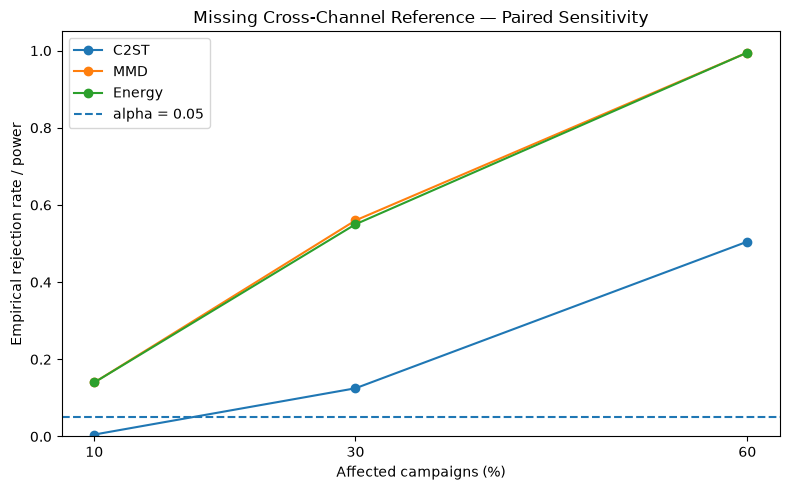

In [45]:
import matplotlib.pyplot as plt


plt.figure(
    figsize=(8, 5)
)


for metric in [
    "C2ST",
    "MMD",
    "Energy"
]:

    subset = (
        missing_reference_power_summary[
            missing_reference_power_summary[
                "metric"
            ] == metric
        ]
        .sort_values(
            "severity"
        )
    )

    plt.plot(
        subset[
            "severity"
        ] * 100,

        subset[
            "power"
        ],

        marker="o",
        label=metric
    )


plt.axhline(
    ALPHA,
    linestyle="--",
    label="alpha = 0.05"
)

plt.xlabel(
    "Affected campaigns (%)"
)

plt.ylabel(
    "Empirical rejection rate / power"
)

plt.title(
    "Missing Cross-Channel Reference — "
    "Paired Sensitivity"
)

plt.ylim(
    0,
    1.05
)

plt.xticks(
    [
        10,
        30,
        60
    ]
)

plt.legend()

plt.tight_layout()

plt.show()

In [46]:
semantic_null_results = pd.read_csv(
    "../results/"
    "entity_inconsistency_clean_null.csv"
)


semantic_null_summary = (
    semantic_null_results
    .groupby(
        "metric"
    )
    .agg(
        rejections=(
            "reject",
            "sum"
        ),

        type_I_error=(
            "reject",
            "mean"
        ),

        mean_p_value=(
            "p_value",
            "mean"
        )
    )
    .reset_index()
)


display(
    semantic_null_summary
)

,metric,rejections,type_I_error,mean_p_value
0,C2ST,7,0.035,0.549234
1,Energy,11,0.055,0.505050
2,MMD,11,0.055,0.505743


In [47]:
missing_reference_power_summary.to_csv(
    "../results/"
    "missing_cross_channel_"
    "power_summary.csv",
    index=False
)

missing_reference_affected_summary.to_csv(
    "../results/"
    "missing_cross_channel_"
    "affected_sample_summary.csv"
)

print(
    "Missing Cross-Channel Reference "
    "summaries saved."
)

Missing Cross-Channel Reference summaries saved.


### Missing Cross-Channel Reference — Paired Sensitivity Results

Missing Cross-Channel Reference produced a clear prevalence-dependent
response across all three metrics. MMD and Energy Distance showed nearly
identical sensitivity, with empirical power of 0.140 at 10% defect
prevalence, approximately 0.55–0.56 at 30%, and 0.995 at 60%.

C2ST was substantially less sensitive. Its rejection rate increased from
0.005 at 10% prevalence to 0.125 at 30% and 0.505 at 60%. Thus, although
the classifier became increasingly capable of distinguishing clean and
defective campaign embeddings as prevalence increased, it remained much
less sensitive than the kernel- and distance-based tests.

The observed sampling behavior was consistent with the intended severity
design. Across 200 repetitions, samples of 100 campaigns contained an
average of 9.93, 29.75, and 59.80 affected campaigns for the nominal
10%, 30%, and 60% conditions, respectively.

An important contrast emerges when these results are compared with Entity
Inconsistency. Missing Cross-Channel Reference caused a larger average
clean-to-defective displacement in the semantic embedding space, yet MMD
and Energy Distance exhibited lower power at low and medium prevalence.
This demonstrates that the magnitude of paired representation change alone
does not determine two-sample detectability. A defect may produce relatively
large but heterogeneous embedding perturbations without inducing an equally
strong or coherent distributional shift.

The result therefore reinforces the distinction between defect magnitude,
representation response, and metric sensitivity. The same frozen semantic
representation contains information about the injected cross-channel
inconsistency, but the three statistical tests exploit that information
with substantially different sensitivity.

In [55]:
# -----------------------------------------
# Validate campaign ID alignment
# -----------------------------------------

clean_ids = (
    missing_reference_embeddings[
        "clean"
    ]["campaign_id"]
    .to_numpy()
)

print(
    "Number of clean campaign IDs:",
    len(clean_ids)
)

print(
    "Unique clean campaign IDs:",
    len(
        np.unique(clean_ids)
    )
)

print(
    "First 10 campaign IDs:"
)

print(
    clean_ids[:10]
)

Number of clean campaign IDs: 300
Unique clean campaign IDs: 300
First 10 campaign IDs:
['C0003' 'C0004' 'C0006' 'C0008' 'C0010' 'C0011' 'C0024' 'C0026' 'C0030'
 'C0031']


In [56]:
conditions = [
    "clean",
    0.10,
    0.30,
    0.60
]


reference_ids = (
    missing_reference_embeddings[
        "clean"
    ]["campaign_id"]
    .to_numpy()
)


for condition in conditions:

    condition_ids = (
        missing_reference_embeddings[
            condition
        ]["campaign_id"]
        .to_numpy()
    )

    same_order = np.array_equal(
        reference_ids,
        condition_ids
    )

    print(
        f"{condition}: "
        f"same campaign order = "
        f"{same_order}"
    )

    assert same_order


print(
    "Campaign ID alignment "
    "passed for all conditions."
)

clean: same campaign order = True
0.1: same campaign order = True
0.3: same campaign order = True
0.6: same campaign order = True
Campaign ID alignment passed for all conditions.


In [57]:
for condition in conditions:

    X = (
        missing_reference_embedding_arrays[
            condition
        ]
    )

    ids = (
        missing_reference_embeddings[
            condition
        ]["campaign_id"]
        .to_numpy()
    )

    print(
        f"{condition}: "
        f"embeddings={X.shape}, "
        f"IDs={len(ids)}"
    )

    assert (
        X.shape[0]
        ==
        len(ids)
    )


print(
    "Each embedding row has "
    "exactly one campaign ID."
)

clean: embeddings=(300, 384), IDs=300
0.1: embeddings=(300, 384), IDs=300
0.3: embeddings=(300, 384), IDs=300
0.6: embeddings=(300, 384), IDs=300
Each embedding row has exactly one campaign ID.


In [58]:
missing_reference_embedding_ids = (
    missing_reference_embeddings[
        "clean"
    ][
        ["campaign_id"]
    ]
    .copy()
)


missing_reference_embedding_ids.to_csv(
    "../data/processed/"
    "missing_reference_"
    "embedding_campaign_ids.csv",
    index=False
)


print(
    "Campaign IDs saved."
)

print(
    "Shape:",
    missing_reference_embedding_ids.shape
)

display(
    missing_reference_embedding_ids.head()
)

Campaign IDs saved.
Shape: (300, 1)


,campaign_id
0,C0003
1,C0004
2,C0006
3,C0008
4,C0010


In [59]:
# Save row-to-campaign mapping
missing_reference_embeddings[
    "clean"
][
    ["campaign_id"]
].to_csv(
    "../data/processed/"
    "missing_reference_"
    "embedding_campaign_ids.csv",
    index=False
)

In [60]:
import importlib
import src.io_utils as io_utils

importlib.reload(
    io_utils
)

from src.io_utils import (
    save_affected_ids_by_severity
)


missing_affected_ids = {
    severity:
        missing_reference_results[
            severity
        ]["audit"][
            "campaign_id"
        ].to_numpy()

    for severity in [
        0.10,
        0.30,
        0.60
    ]
}


missing_affected_df = (
    save_affected_ids_by_severity(
        missing_affected_ids,

        "../data/processed/"
        "missing_reference_"
        "affected_campaign_ids.csv",

        id_column="campaign_id"
    )
)


display(
    missing_affected_df.groupby(
        "severity"
    ).size()
)

severity
0.1     30
0.3     90
0.6    180
dtype: int64